# Final Data Science Capstone Project
## Income Drivers and a Fairness-Audited Prediction Model – 48,842 census records
**Task 6 – Yuva Intern | AI/ML Research Specialist Internship**

Pipeline: **problem definition → data collection & preparation → statistical analysis → machine learning → evaluation (including bias and limitations) → visualisation → recommendations → presentation.**

## 1. Problem Definition
**Real-world problem.** Governments, banks and non-profits use income-related models to target financial-inclusion, skills-training and outreach programmes. Two questions matter: *(a) what characteristics are associated with high income?* and *(b) if we build a model that predicts high income, is it accurate, well calibrated and fair to the groups it will be applied to?*

**Dataset.** The UCI *Adult* (Census Income) dataset, extracted from the 1994 US Census database: 48,842 people, 14 attributes (age, work class, education, marital status, occupation, relationship, race, sex, capital gains/losses, hours per week, native country) and a label: income above or below $50,000 per year.

| Element | Statement |
|---|---|
| **Problem statement** | Identify the factors associated with annual income above $50K, build a classifier, and audit it for accuracy, calibration and group fairness |
| **Objectives** | (1) clean and document the data; (2) test the main relationships statistically; (3) build and compare models; (4) evaluate with suitable metrics; (5) quantify bias and limitations; (6) turn findings into recommendations |
| **Scope** | Descriptive and predictive analysis of one historical snapshot. No causal claims |
| **Requirements** | Reproducible notebook, report with numbers for every claim, presentation, GitHub repository |
| **Expected outcomes** | A tested ranking of income-related factors; a classifier with AUC above 0.90; a fairness audit identifying where the model treats groups differently |

> **Ethical note.** Sex and race appear in this dataset. They are analysed here to *audit* for disparities, not to recommend using them for decisions. All results describe 1994 data and must not be applied to current populations without revalidation.

In [1]:
import os, json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.api as sm, statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid", palette="deep")
os.makedirs("images", exist_ok=True)
SEED = 42; rng = np.random.default_rng(SEED); M = {}
f = lambda v: float(np.round(v, 4))
def save(name): plt.tight_layout(); plt.savefig(f"images/{name}.png", dpi=130); plt.show()

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/adult-all.csv"
cols = ["age", "workclass", "fnlwgt", "education", "education_num", "marital_status", "occupation", "relationship", "race", "sex",
        "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"]
try: raw = pd.read_csv("data/adult_raw.csv", header=None, names=cols, skipinitialspace=True, na_values="?")
except FileNotFoundError:
    pd.read_csv(URL, header=None).to_csv("data/adult_raw.csv", header=False, index=False)
    raw = pd.read_csv("data/adult_raw.csv", header=None, names=cols, skipinitialspace=True, na_values="?")
raw["income"] = raw.income.str.strip().str.rstrip(".")
print(raw.shape); raw.head()

(48842, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 2. Data Collection & Preparation

### 2.1 Quality audit

In [2]:
dups = int(raw.duplicated().sum()); print("Exact duplicate rows:", dups)
miss = raw.isna().sum(); miss = miss[miss > 0]; print("Missing values (coded '?' in source):\n", miss, "\n")
print("capital_gain == 99999 (top-coded placeholder):", int((raw.capital_gain == 99999).sum()), "| age == 90 (top-coded):", int((raw.age == 90).sum()))
print("education vs education_num one-to-one:", raw.groupby("education").education_num.nunique().max() == 1, "(redundant columns)")
print("Income label balance:", raw.income.value_counts(normalize=True).round(3).to_dict())
M.update(rows=len(raw), cols=raw.shape[1], dups=dups, miss_work=int(raw.workclass.isna().sum()), miss_occ=int(raw.occupation.isna().sum()), miss_nat=int(raw.native_country.isna().sum()),
         cg_top=int((raw.capital_gain == 99999).sum()), age90=int((raw.age == 90).sum()), pos_rate=f((raw.income == ">50K").mean()))

Exact duplicate rows: 52
Missing values (coded '?' in source):
 workclass         2799
occupation        2809
native_country     857
dtype: int64 

capital_gain == 99999 (top-coded placeholder): 244 | age == 90 (top-coded): 55
education vs education_num one-to-one: True (redundant columns)
Income label balance: {'<=50K': 0.761, '>50K': 0.239}


### 2.2 Is the missing data random? (a bias check done before filling anything)

In [3]:
ms = raw.occupation.isna(); hi = (raw.income == ">50K")
print(f">50K rate: occupation missing {hi[ms].mean():.1%} (n={ms.sum():,}) vs present {hi[~ms].mean():.1%} (n={(~ms).sum():,})")
chi, p, *_ = stats.chi2_contingency(pd.crosstab(ms, hi)); print(f"chi2 = {chi:.1f}, p = {p:.1e}  -> missingness is related to the outcome (not missing at random)")
print("Mean age when occupation missing:", raw.age[ms].mean().round(1), "vs", raw.age[~ms].mean().round(1))
M.update(miss_rate_hi=f(hi[ms].mean()), pres_rate_hi=f(hi[~ms].mean()), miss_chi=f(chi), miss_age=f(raw.age[ms].mean()), pres_age=f(raw.age[~ms].mean()))

>50K rate: occupation missing 9.4% (n=2,809) vs present 24.8% (n=46,033)
chi2 = 343.1, p = 1.3e-76  -> missingness is related to the outcome (not missing at random)
Mean age when occupation missing: 40.1 vs 38.6


**Decision:** rows are *not* dropped (that would remove 2,809 people who differ systematically); missing categories are kept as an explicit `Unknown` level so the model and the audit can see them.

### 2.3 Cleaning and feature engineering

In [4]:
df = raw.drop_duplicates().reset_index(drop=True)
for c in ["workclass", "occupation", "native_country"]: df[c] = df[c].fillna("Unknown")
df["y"] = (df.income == ">50K").astype(int)
df["married"] = df.marital_status.isin(["Married-civ-spouse", "Married-AF-spouse"]).map({True: "Married", False: "Not married"})
df["age_band"] = pd.cut(df.age, [16, 24, 34, 44, 54, 64, 100], labels=["17-24", "25-34", "35-44", "45-54", "55-64", "65+"])
df["hours_band"] = pd.cut(df.hours_per_week, [0, 34, 40, 50, 100], labels=["part-time (<35)", "35-40", "41-50", ">50"])
df["has_capital_gain"] = (df.capital_gain > 0).astype(int); df["has_capital_loss"] = (df.capital_loss > 0).astype(int)
df["native_us"] = (df.native_country == "United-States").map({True: "US", False: "Non-US/Unknown"})
df["edu_group"] = pd.cut(df.education_num, [0, 8, 9, 12, 13, 16], labels=["< HS", "HS grad", "Some college/assoc", "Bachelors", "Masters/Prof/PhD"])
df.to_csv("data/adult_clean.csv", index=False)
n = len(df); M.update(n=n, removed=len(raw) - n, pos=int(df.y.sum()), pos_rate_clean=f(df.y.mean()))
print(f"{len(raw):,} -> {n:,} rows | >50K: {df.y.sum():,} ({df.y.mean():.1%})")
df.select_dtypes("object").nunique().to_frame("distinct values").T

48,842 -> 48,790 rows | >50K: 11,681 (23.9%)


,workclass,education,marital_status,occupation,relationship,race,sex,native_country,income,married,native_us
distinct values,9,16,7,15,6,5,2,42,2,2,2


## 3. Exploratory Analysis

In [5]:
num = ["age", "education_num", "hours_per_week", "capital_gain", "capital_loss"]
sm_ = df.groupby("income")[num].agg(["mean", "median"]).round(1); print(sm_.T)
M["num_summary"] = {c: {"mean_hi": f(df[df.y == 1][c].mean()), "mean_lo": f(df[df.y == 0][c].mean()), "med_hi": f(df[df.y == 1][c].median()), "med_lo": f(df[df.y == 0][c].median())} for c in num}
print(f"\nShare with any capital gain: {df.has_capital_gain.mean():.1%} overall | among >50K: {df[df.y==1].has_capital_gain.mean():.1%} | among <=50K: {df[df.y==0].has_capital_gain.mean():.1%}")
def rate(col):
    g = df.groupby(col, observed=True).y.agg(["size", "sum", "mean"]); g.columns = ["n", "high_income", "rate"]; return g.round(4)
R = {c: rate(c) for c in ["sex", "race", "married", "edu_group", "age_band", "hours_band", "workclass", "occupation"]}
for c in ["sex", "married", "edu_group", "age_band", "hours_band"]: print(f"\n--- >50K rate by {c} ---"); print(R[c])
M["rates"] = {k: v.reset_index().astype({k: str}).to_dict("records") for k, v in R.items()}

income                 <=50K    >50K
age            mean     36.9    44.3
               median   34.0    43.0
education_num  mean      9.6    11.6
               median    9.0    12.0
hours_per_week mean     38.8    45.5
               median   40.0    40.0
capital_gain   mean    147.2  4044.3
               median    0.0     0.0
capital_loss   mean     54.2   193.6
               median    0.0     0.0

Share with any capital gain: 8.3% overall | among >50K: 21.3% | among <=50K: 4.2%



--- >50K rate by sex ---
            n  high_income    rate
sex                               
Female  16176         1769  0.1094
Male    32614         9912  0.3039

--- >50K rate by married ---
                 n  high_income   rate
married                               
Married      22403         9992  0.446
Not married  26387         1689  0.064

--- >50K rate by edu_group ---
                        n  high_income    rate
edu_group                                     
< HS                 6399          366  0.0572
HS grad             15770         2501  0.1586
Some college/assoc  14524         2996  0.2063
Bachelors            8013         3311  0.4132
Masters/Prof/PhD     4084         2507  0.6139

--- >50K rate by age_band ---
              n  high_income    rate
age_band                            
17-24      8409           93  0.0111
25-34     12564         2115  0.1683
35-44     12184         4055  0.3328
45-54      8765         3453  0.3940
55-64      4782         1538  0.32

## 4. Statistical Analysis
Every test states the hypotheses, shows counts/means, gives the statistic, p-value and an **effect size**, and explains **what the result means** and **possible reasons** (clearly separated from what the data can prove).

### 4.1 Sex and high income: chi-square test of independence

In [6]:
t = pd.crosstab(df.sex, df.income); chi, p, dof, exp = stats.chi2_contingency(t); V = np.sqrt(chi / (t.values.sum() * (min(t.shape) - 1)))
print(t, "\n\nExpected under independence:\n", pd.DataFrame(exp, index=t.index, columns=t.columns).round(0))
rf, rm = t.loc["Female", ">50K"] / t.loc["Female"].sum(), t.loc["Male", ">50K"] / t.loc["Male"].sum()
print(f"\nHigh-income rate: women {rf:.1%}, men {rm:.1%}; ratio {rm/rf:.2f}x; gap {(rm-rf)*100:.1f} pp")
print(f"chi2 = {chi:,.1f}, dof = {dof}, p = {p:.1e}, Cramer's V = {V:.3f}")
bs = np.array([rng.choice(df[df.sex == "Male"].y.to_numpy(), (df.sex == "Male").sum()).mean() - rng.choice(df[df.sex == "Female"].y.to_numpy(), (df.sex == "Female").sum()).mean() for _ in range(1000)])
bl, bh = np.percentile(bs, [2.5, 97.5]); print(f"Bootstrap 95% CI for the gap: ({bl*100:.1f}, {bh*100:.1f}) pp")
M.update(sex_obs=t.reset_index().to_dict("records"), sex_exp=pd.DataFrame(exp, index=t.index, columns=t.columns).round(0).reset_index().to_dict("records"), sex_chi=f(chi), sex_V=f(V),
         rate_f=f(rf), rate_m=f(rm), sex_gap=f((rm - rf) * 100), sex_boot_lo=f(bl * 100), sex_boot_hi=f(bh * 100), sex_ratio=f(rm / rf), n_f=int(t.loc["Female"].sum()), n_m=int(t.loc["Male"].sum()))

income  <=50K  >50K
sex                
Female  14407  1769
Male    22702  9912 

Expected under independence:
 income    <=50K    >50K
sex                    
Female  12303.0  3873.0
Male    24806.0  7808.0

High-income rate: women 10.9%, men 30.4%; ratio 2.78x; gap 19.5 pp
chi2 = 2,246.7, dof = 1, p = 0.0e+00, Cramer's V = 0.215


Bootstrap 95% CI for the gap: (18.8, 20.2) pp


**What it means.** The raw gap is large and statistically certain. But the *reasons* are not established by this test. Possible contributors (hypotheses to be checked, not conclusions): differences in marital status and household structure in the data (see 4.6), hours worked, occupation mix, career interruptions, and pay discrimination. Section 4.6 tests how much of the gap survives statistical adjustment.

### 4.2 Chi-square tests for all categorical features (Holm-corrected)

In [7]:
cats = ["workclass", "education", "marital_status", "occupation", "relationship", "race", "sex", "native_us", "age_band", "hours_band"]
rows = []
for c in cats:
    tt = pd.crosstab(df[c], df.y); chi_, pv, d_, _ = stats.chi2_contingency(tt); rows.append((c, d_, chi_, pv, np.sqrt(chi_ / (tt.values.sum() * (min(tt.shape) - 1)))))
ct = pd.DataFrame(rows, columns=["feature", "dof", "chi2", "p_raw", "cramers_v"]); ct["p_holm"] = multipletests(ct.p_raw, method="holm")[1]
ct = ct.sort_values("cramers_v", ascending=False).reset_index(drop=True); print(ct.round(4).to_string(index=False)); M["chi_tab"] = ct.round(4).to_dict("records")

       feature  dof       chi2  p_raw  cramers_v  p_holm
  relationship    5 10070.6319    0.0     0.4543     0.0
marital_status    6  9797.1413    0.0     0.4481     0.0
     education   15  6536.4663    0.0     0.3660     0.0
    occupation   14  5975.4744    0.0     0.3500     0.0
      age_band    5  4681.1433    0.0     0.3097     0.0
    hours_band    3  3537.4102    0.0     0.2693     0.0
           sex    1  2246.6893    0.0     0.2146     0.0
     workclass    8  1609.5002    0.0     0.1816     0.0
          race    4   487.4855    0.0     0.1000     0.0
     native_us    1    50.4917    0.0     0.0322     0.0


**Reading the table.** With 48,000 rows almost everything is significant, so the *strength* (Cramér's V: <0.1 weak, 0.1–0.3 moderate, >0.3 strong) is what matters. Relationship (a household-role variable) and marital status are the strongest categorical associates, ahead of education and occupation. That marital status ranks so high is itself a finding about the *data* (household income pooling and age effects), not evidence that marriage causes high income.

### 4.3 Hours worked and age: Welch t-test, Mann-Whitney, effect size

In [8]:
out = {}
for c in ["hours_per_week", "age", "education_num"]:
    a, b = df[df.y == 1][c], df[df.y == 0][c]; t_, p_ = stats.ttest_ind(a, b, equal_var=False); u, pu = stats.mannwhitneyu(a, b)
    sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2)); d = (a.mean() - b.mean()) / sp
    se = np.sqrt(a.var() / len(a) + b.var() / len(b)); ci = (a.mean() - b.mean()) + np.array([-1.96, 1.96]) * se
    print(f"{c:<15} >50K mean {a.mean():5.2f} vs <=50K {b.mean():5.2f} | diff {a.mean()-b.mean():+.2f} (95% CI {ci[0]:+.2f}, {ci[1]:+.2f}) | Welch t = {t_:6.1f}, MWU p = {pu:.1e} | d = {d:.2f}")
    out[c] = dict(hi=f(a.mean()), lo=f(b.mean()), diff=f(a.mean() - b.mean()), ci_lo=f(ci[0]), ci_hi=f(ci[1]), t=f(t_), d=f(d))
M["ttests"] = out

hours_per_week  >50K mean 45.45 vs <=50K 38.84 | diff +6.61 (95% CI +6.37, +6.85) | Welch t =   54.6, MWU p = 0.0e+00 | d = 0.55
age             >50K mean 44.28 vs <=50K 36.88 | diff +7.39 (95% CI +7.15, +7.63) | Welch t =   60.6, MWU p = 0.0e+00 | d = 0.55
education_num   >50K mean 11.60 vs <=50K  9.60 | diff +2.00 (95% CI +1.95, +2.05) | Welch t =   78.9, MWU p = 0.0e+00 | d = 0.83


**What it means.** High earners work about 6.6 more hours per week, are about 7.4 years older and have about 2.0 more years of education. Education has the largest effect (d = 0.83, large); age and hours are medium effects (d = 0.55 each). **Possible reasons:** education raises access to higher-paid occupations; age proxies experience and seniority (wages rise with age until late career); longer hours reflect both overtime/self-employment and the fact that salaried managers often work longer weeks. Reverse and common-cause explanations cannot be excluded.

### 4.4 ANOVA, Kruskal-Wallis and Tukey: hours per week across marital status

In [9]:
groups = [g.hours_per_week.to_numpy() for _, g in df.groupby("marital_status")]; F, pa = stats.f_oneway(*groups); H, pk = stats.kruskal(*groups)
grand = df.hours_per_week.mean(); eta2 = sum(len(g) * (g.mean() - grand) ** 2 for g in groups) / ((df.hours_per_week - grand) ** 2).sum()
print(df.groupby("marital_status").hours_per_week.agg(["size", "mean"]).round(1)); print(f"\nANOVA F = {F:.1f}, p = {pa:.1e}, eta2 = {eta2:.3f}; Kruskal-Wallis H = {H:.0f}")
M.update(anova_F=f(F), anova_eta2=f(eta2), kw_H=f(H), hours_by_marital=df.groupby("marital_status").hours_per_week.agg(["size", "mean"]).round(1).reset_index().to_dict("records"))

                        size  mean
marital_status                    
Divorced                6630  41.1
Married-AF-spouse         37  39.8
Married-civ-spouse     22366  43.3
Married-spouse-absent    627  39.7
Never-married          16082  36.9
Separated               1530  39.7
Widowed                 1518  33.4

ANOVA F = 537.7, p = 0.0e+00, eta2 = 0.062; Kruskal-Wallis H = 3597


### 4.5 Correlation structure

In [10]:
cm = df[["age", "education_num", "hours_per_week", "capital_gain", "capital_loss", "y"]].corr(); sp_ = df[["age", "education_num", "hours_per_week", "capital_gain", "y"]].corr("spearman")
print(cm.round(3)); print("\nSpearman with outcome:", sp_["y"].round(3).to_dict())
M.update(corr_y=cm["y"].round(3).to_dict(), spear_y=sp_["y"].round(3).to_dict())

                  age  education_num  hours_per_week  capital_gain  \
age             1.000          0.031           0.071         0.077   
education_num   0.031          1.000           0.144         0.125   
hours_per_week  0.071          0.144           1.000         0.082   
capital_gain    0.077          0.125           0.082         1.000   
capital_loss    0.057          0.081           0.054        -0.031   
y               0.230          0.333           0.228         0.223   

                capital_loss      y  
age                    0.057  0.230  
education_num          0.081  0.333  
hours_per_week         0.054  0.228  
capital_gain          -0.031  0.223  
capital_loss           1.000  0.148  
y                      0.148  1.000  

Spearman with outcome: {'age': 0.269, 'education_num': 0.328, 'hours_per_week': 0.268, 'capital_gain': 0.278, 'y': 1.0}


**Note:** capital gain has a weak Pearson correlation with income (heavy zero-inflation, a few extreme values and the 99,999 placeholder) but a much stronger rank correlation: almost everyone with a positive capital gain is high-income.

### 4.6 Does the gender gap survive adjustment? Logistic regression and confounding
The raw gap (4.1) mixes several effects. A logistic regression compares men and women **with the same age, education, hours, occupation and marital status**. A *large drop* in the odds ratio means the raw gap is largely explained by those variables; a *remaining* gap means unexplained variation (which could be discrimination, but also unmeasured factors such as experience or career interruptions).

In [11]:
m0 = smf.logit("y ~ C(sex, Treatment('Female'))", data=df).fit(disp=0)
m1 = smf.logit("y ~ C(sex, Treatment('Female')) + age + I(age**2) + education_num + hours_per_week", data=df).fit(disp=0)
m2 = smf.logit("y ~ C(sex, Treatment('Female')) + age + I(age**2) + education_num + hours_per_week + C(occupation) + C(workclass) + C(married)", data=df).fit(disp=0)
k = "C(sex, Treatment('Female'))[T.Male]"; tab = []
for nme, m in [("Unadjusted", m0), ("+ age, education, hours", m1), ("+ occupation, workclass, marital status", m2)]:
    ci = np.exp(m.conf_int().loc[k]); tab.append((nme, np.exp(m.params[k]), ci[0], ci[1], m.prsquared)); print(f"{nme:<42} OR(male) = {np.exp(m.params[k]):.2f} (95% CI {ci[0]:.2f}-{ci[1]:.2f}), pseudo-R2 = {m.prsquared:.3f}")
M["sex_or"] = [dict(model=a, OR=f(b), lo=f(c), hi=f(d), r2=f(e)) for a, b, c, d, e in tab]
mar = pd.crosstab(df.sex, df.married, normalize="index").round(3); print("\nShare married:\n", mar); M["married_by_sex"] = mar.reset_index().to_dict("records")
print("\nMedian hours/week:", df.groupby("sex").hours_per_week.median().to_dict(), "| mean age:", df.groupby("sex").age.mean().round(1).to_dict())
M.update(hrs_f=f(df[df.sex == "Female"].hours_per_week.mean()), hrs_m=f(df[df.sex == "Male"].hours_per_week.mean()))

Unadjusted                                 OR(male) = 3.56 (95% CI 3.37-3.76), pseudo-R2 = 0.046
+ age, education, hours                    OR(male) = 3.23 (95% CI 3.04-3.43), pseudo-R2 = 0.251
+ occupation, workclass, marital status    OR(male) = 1.18 (95% CI 1.09-1.27), pseudo-R2 = 0.367

Share married:
 married  Married  Not married
sex                          
Female     0.155        0.845
Male       0.610        0.390

Median hours/week: {'Female': 40.0, 'Male': 40.0} | mean age: {'Female': 36.9, 'Male': 39.5}


**What it means.** Adjusting for age, education and hours barely moves the male odds ratio (3.56 to 3.23). Adding occupation, work class and marital status cuts it to 1.18 (95% CI 1.09–1.27): the gap shrinks by almost 90% on the odds scale but does not reach 1. The marital-status variable does most of the work: only 15.5% of women but 61.0% of men are coded 'married' in this data, and *within* the married group women and men have almost identical high-income rates (44.8% vs 44.6%), while among the unmarried the rates are 4.7% (women) vs 8.2% (men). This is a textbook case of **confounding / Simpson-type composition effects**. What remains after adjustment is *unexplained*, not *proven discrimination*: it could reflect unmeasured experience, career breaks, industry, or how the household-oriented marital variable is coded in 1994 census data.

### 4.7 Multivariate model for income drivers (odds ratios)

In [12]:
full = smf.logit("y ~ age + I(age**2) + education_num + hours_per_week + has_capital_gain + has_capital_loss + C(married) + C(sex, Treatment('Female')) + C(race, Treatment('White')) + C(native_us)", data=df).fit(disp=0)
orx = pd.DataFrame({"OR": np.exp(full.params), "lo": np.exp(full.conf_int()[0]), "hi": np.exp(full.conf_int()[1]), "p": full.pvalues}).drop("Intercept").round(3)
orx.index = [i.replace("C(married)[T.", "married: ").replace("C(sex, Treatment('Female'))[T.", "sex: ").replace("C(race, Treatment('White'))[T.", "race: ").replace("C(native_us)[T.", "native: ").replace("]", "") for i in orx.index]
print(f"pseudo-R2 = {full.prsquared:.3f}, n = {int(full.nobs):,}"); print(orx.sort_values("OR", ascending=False).to_string())
M.update(full_r2=f(full.prsquared), orx=orx.reset_index().rename(columns={"index": "factor"}).to_dict("records"))
M["or_edu_year"] = f(np.exp(full.params["education_num"])); M["or_hours_10"] = f(np.exp(10 * full.params["hours_per_week"]))

pseudo-R2 = 0.378, n = 48,790
                             OR     lo     hi      p
has_capital_gain          5.683  5.206  6.203  0.000
has_capital_loss          3.181  2.848  3.553  0.000
education_num             1.431  1.413  1.448  0.000
native: US                1.275  1.146  1.419  0.000
age                       1.269  1.250  1.289  0.000
sex: Male                 1.131  1.050  1.219  0.001
hours_per_week            1.025  1.023  1.027  0.000
I(age ** 2)               0.998  0.998  0.998  0.000
race: Asian-Pac-Islander  0.948  0.800  1.124  0.539
race: Other               0.835  0.574  1.215  0.347
race: Black               0.743  0.664  0.831  0.000
race: Amer-Indian-Eskimo  0.611  0.439  0.851  0.004
married: Not married      0.109  0.102  0.117  0.000


## 5. Machine Learning

In [13]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, brier_score_loss, confusion_matrix, roc_curve, precision_recall_curve)
from sklearn.inspection import permutation_importance

num_f = ["age", "education_num", "hours_per_week", "capital_gain", "capital_loss"]
cat_f = ["workclass", "marital_status", "occupation", "relationship", "race", "sex", "native_us"]
X = df[num_f + cat_f]; y = df.y
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print(f"Train {len(Xtr):,} | Test {len(Xte):,} | positive rate train {ytr.mean():.3f}, test {yte.mean():.3f}")
def pipe(model, cats=cat_f, nums=num_f, scale=False, ordinal=False):
    enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1) if ordinal else OneHotEncoder(handle_unknown="ignore")
    return Pipeline([("p", ColumnTransformer([("n", StandardScaler() if scale else "passthrough", nums), ("c", enc, cats)])), ("m", model)])
def hgb(cats=cat_f, nums=num_f):
    p = pipe(HistGradientBoostingClassifier(max_iter=250, learning_rate=0.08, random_state=SEED), cats, nums, ordinal=True)
    p.named_steps["m"].set_params(categorical_features=list(range(len(nums), len(nums) + len(cats)))); return p
models = {"Baseline (majority class)": pipe(DummyClassifier(strategy="most_frequent")), "Logistic Regression": pipe(LogisticRegression(max_iter=2000), scale=True),
          "Random Forest": pipe(RandomForestClassifier(n_estimators=150, min_samples_leaf=3, n_jobs=-1, random_state=SEED), ordinal=True), "Gradient Boosting (HGB)": hgb()}
rows = []; fit = {}; skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
for nme, m in models.items():
    cv = cross_val_score(m, Xtr, ytr, cv=skf, scoring="roc_auc") if "Baseline" not in nme else np.array([0.5] * 5)
    m.fit(Xtr, ytr); pr = m.predict_proba(Xte)[:, 1]; yh = (pr >= 0.5).astype(int); fit[nme] = m
    rows.append(dict(model=nme, accuracy=accuracy_score(yte, yh), precision=precision_score(yte, yh, zero_division=0), recall=recall_score(yte, yh), f1=f1_score(yte, yh), roc_auc=roc_auc_score(yte, pr),
                     pr_auc=average_precision_score(yte, pr), cv_auc=cv.mean(), cv_std=cv.std()))
res = pd.DataFrame(rows).round(4); print(res.to_string(index=False)); M["models"] = res.to_dict("records"); M.update(train_n=len(Xtr), test_n=len(Xte), test_pos=f(yte.mean()))

Train 36,592 | Test 12,198 | positive rate train 0.239, test 0.239


                    model  accuracy  precision  recall     f1  roc_auc  pr_auc  cv_auc  cv_std
Baseline (majority class)    0.7606     0.0000  0.0000 0.0000   0.5000  0.2394  0.5000  0.0000
      Logistic Regression    0.8530     0.7305  0.6116 0.6658   0.9067  0.7651  0.9058  0.0040
            Random Forest    0.8671     0.7694  0.6353 0.6959   0.9191  0.8115  0.9167  0.0054
  Gradient Boosting (HGB)    0.8754     0.7820  0.6647 0.7186   0.9306  0.8358  0.9273  0.0046


In [14]:
best = fit["Gradient Boosting (HGB)"]; pr = best.predict_proba(Xte)[:, 1]; yh = (pr >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(yte, yh).ravel(); print(f"Confusion matrix @0.5 -> TN {tn:,} FP {fp:,} FN {fn:,} TP {tp:,}")
print(f"Accuracy {accuracy_score(yte, yh):.3f} vs majority baseline {1 - yte.mean():.3f} (accuracy alone is misleading: {1 - yte.mean():.1%} are <=50K)")
M.update(tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp), base_acc=f(1 - yte.mean()))

Confusion matrix @0.5 -> TN 8,737 FP 541 FN 979 TP 1,941
Accuracy 0.875 vs majority baseline 0.761 (accuracy alone is misleading: 76.1% are <=50K)


### 5.1 Threshold analysis

In [15]:
rows = []
for th in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    h = (pr >= th).astype(int); rows.append(dict(threshold=th, flagged=int(h.sum()), precision=precision_score(yte, h), recall=recall_score(yte, h), f1=f1_score(yte, h)))
thr = pd.DataFrame(rows).round(3); print(thr.to_string(index=False)); M["thr"] = thr.to_dict("records")
best_th = thr.sort_values("f1").iloc[-1].threshold; print("Best F1 threshold:", best_th); M["best_th"] = float(best_th)

 threshold  flagged  precision  recall    f1
       0.2     4521      0.577   0.893 0.701
       0.3     3779      0.637   0.824 0.719
       0.4     3066      0.709   0.744 0.726
       0.5     2482      0.782   0.665 0.719
       0.6     2045      0.843   0.590 0.694
       0.7     1552      0.911   0.484 0.632
Best F1 threshold: 0.4


### 5.2 Feature importance (permutation, drop in AUC)

In [16]:
idx = Xte.sample(6000, random_state=SEED).index
pi = permutation_importance(best, Xte.loc[idx], yte.loc[idx], n_repeats=5, random_state=SEED, scoring="roc_auc")
imp = pd.Series(pi.importances_mean, index=Xte.columns).sort_values(ascending=False).round(4); print(imp); M["imp"] = imp.to_dict()

capital_gain      0.0586
age               0.0509
marital_status    0.0304
education_num     0.0213
occupation        0.0185
relationship      0.0143
capital_loss      0.0141
hours_per_week    0.0110
workclass         0.0024
race              0.0011
sex               0.0011
native_us        -0.0000
dtype: float64


## 6. Evaluation: Calibration, Stability and Limits of the Model
Accuracy and AUC describe *ranking* quality. A model used for decisions must also be **calibrated** (a predicted 70% really means ~70%), **stable** (not dependent on tiny data changes or on an unrepresentative group) and **fair**.

### 6.1 Calibration

In [17]:
brier = brier_score_loss(yte, pr); brier_base = brier_score_loss(yte, np.full(len(yte), ytr.mean()))
cal = pd.DataFrame({"p": pr, "y": yte.values}); cal["bin"] = pd.cut(cal.p, np.linspace(0, 1, 11), include_lowest=True)
ct_ = cal.groupby("bin", observed=True).agg(n=("y", "size"), mean_pred=("p", "mean"), actual=("y", "mean")).round(3); ece = (ct_.n * (ct_.mean_pred - ct_.actual).abs()).sum() / ct_.n.sum()
print(ct_); print(f"\nBrier = {brier:.4f} (no-skill {brier_base:.4f}) | Expected calibration error = {ece:.4f}"); M.update(brier=f(brier), brier_base=f(brier_base), ece=f(ece), cal=ct_.reset_index().astype({"bin": str}).to_dict("records"))

                  n  mean_pred  actual
bin                                   
(-0.001, 0.1]  6604      0.021   0.020
(0.1, 0.2]     1073      0.147   0.171
(0.2, 0.3]      742      0.250   0.270
(0.3, 0.4]      713      0.351   0.328
(0.4, 0.5]      584      0.451   0.397
(0.5, 0.6]      437      0.549   0.499
(0.6, 0.7]      493      0.649   0.627
(0.7, 0.8]      508      0.746   0.797
(0.8, 0.9]      211      0.846   0.896
(0.9, 1.0]      833      0.984   0.984

Brier = 0.0867 (no-skill 0.1821) | Expected calibration error = 0.0135


### 6.2 Learning curve and bootstrap uncertainty

In [18]:
lc = []
for frac in [0.05, 0.1, 0.25, 0.5, 1.0]:
    sub = Xtr.sample(frac=frac, random_state=SEED); m = hgb().fit(sub, ytr.loc[sub.index]); lc.append((len(sub), roc_auc_score(yte, m.predict_proba(Xte)[:, 1])))
lc = pd.DataFrame(lc, columns=["train_rows", "test_auc"]).round(4); print(lc.to_string(index=False)); M["lc"] = lc.to_dict("records")
aucs = []
for _ in range(300):
    i = rng.integers(0, len(yte), len(yte)); aucs.append(roc_auc_score(yte.to_numpy()[i], pr[i]))
al, ah = np.percentile(aucs, [2.5, 97.5]); print(f"Test AUC {roc_auc_score(yte, pr):.4f}, bootstrap 95% CI ({al:.4f}, {ah:.4f})"); M.update(auc=f(roc_auc_score(yte, pr)), auc_lo=f(al), auc_hi=f(ah))

 train_rows  test_auc
       1830    0.8930
       3659    0.9063
       9148    0.9200
      18296    0.9254
      36592    0.9308


Test AUC 0.9306, bootstrap 95% CI (0.9248, 0.9348)


### 6.3 Robustness to distribution shift (train on younger people, test on older people)

In [19]:
young = df.age <= 40; Xy, yy = X[young], y[young]; Xo, yo = X[~young], y[~young]
ms = hgb().fit(Xy, yy); ps = ms.predict_proba(Xo)[:, 1]
Xo_tr, Xo_te, yo_tr, yo_te = train_test_split(Xo, yo, test_size=0.3, random_state=SEED, stratify=yo); mi = hgb().fit(Xo_tr, yo_tr); pi_ = mi.predict_proba(Xo_te)[:, 1]
print(f"Train age<=40 ({young.sum():,}) -> test age>40 ({(~young).sum():,}): AUC = {roc_auc_score(yo, ps):.4f}; mean predicted {ps.mean():.3f} vs actual rate {yo.mean():.3f}")
print(f"Reference (train on >40, test on >40): AUC = {roc_auc_score(yo_te, pi_):.4f}; mean predicted {pi_.mean():.3f} vs actual {yo_te.mean():.3f}")
M.update(shift_auc=f(roc_auc_score(yo, ps)), shift_pred=f(ps.mean()), shift_act=f(yo.mean()), ref_auc=f(roc_auc_score(yo_te, pi_)), n_young=int(young.sum()), n_old=int((~young).sum()),
         shift_brier=f(brier_score_loss(yo, ps)), ref_brier=f(brier_score_loss(yo_te, pi_)))

Train age<=40 (28,590) -> test age>40 (20,200): AUC = 0.8941; mean predicted 0.334 vs actual rate 0.351
Reference (train on >40, test on >40): AUC = 0.8979; mean predicted 0.355 vs actual 0.350


**What it means.** The age-shift stress test shows only **modest** degradation: AUC 0.894 for older people when trained on younger people, versus 0.898 when trained on older people, and the model slightly under-predicts (mean predicted 33.4% vs actual 35.1%). So the learned relationships transfer reasonably across age groups in this sample. The much larger risk – change *over time* (1994 to today) – cannot be tested with a single-year dataset and should be assumed to be substantial.

### 6.4 Who does the model miss? (error analysis)

In [20]:
te = Xte.assign(y=yte.values, p=pr, pred=yh, married=df.loc[Xte.index, "married"].values); fnr = te[te.y == 1].assign(miss=lambda d: (d.pred == 0)).groupby("married").miss.agg(["size", "mean"]).round(3)
print("False-negative rate among true >50K, by marital group:\n", fnr)
occ = te[te.y == 1].assign(miss=lambda d: (d.pred == 0)).groupby("occupation").miss.agg(["size", "mean"]).query("size >= 40").sort_values("mean", ascending=False).round(3).head(5); print("\nHighest false-negative rate by occupation (n>=40):\n", occ)
M.update(fnr_married=fnr.reset_index().to_dict("records"), fnr_occ=occ.reset_index().to_dict("records"), fnr_all=f(fn / (fn + tp)))

False-negative rate among true >50K, by marital group:
              size   mean
married                 
Married      2503  0.294
Not married   417  0.583

Highest false-negative rate by occupation (n>=40):
                    size   mean
occupation                    
Other-service        53  0.830
Machine-op-inspct    86  0.709
Farming-fishing      41  0.707
Transport-moving    113  0.690
Craft-repair        337  0.638


## 7. Bias & Fairness Audit
**Definitions** (computed for each group on the test set at threshold 0.5):
- **Selection rate** = share predicted >50K. **Demographic parity difference** = gap between groups' selection rates; the **disparate-impact ratio** = lowest ÷ highest selection rate (the "four-fifths rule" flags ratios below 0.80).
- **TPR (recall)** = share of truly high earners the model finds; **FPR** = share of lower earners wrongly flagged; **equalised-odds gap** = largest difference in TPR/FPR between groups.
- Group base rates differ, so equal selection rates would *not* be expected even from a perfectly fair predictor – this is why several metrics are reported together.

In [21]:
def audit(col, min_n=30):
    d = Xte.assign(y=yte.values, p=pr, pred=yh); rows = []
    for g, s in d.groupby(col):
        pos, neg = s[s.y == 1], s[s.y == 0]
        rows.append(dict(group=g, n=len(s), base_rate=s.y.mean(), selection=s.pred.mean(), tpr=pos.pred.mean() if len(pos) else np.nan, fpr=neg.pred.mean() if len(neg) else np.nan,
                         precision=s[s.pred == 1].y.mean() if s.pred.sum() else np.nan, auc=roc_auc_score(s.y, s.p) if s.y.nunique() == 2 else np.nan, n_pos=len(pos)))
    return pd.DataFrame(rows).round(3)
fa_sex = audit("sex"); fa_race = audit("race"); print(fa_sex.to_string(index=False), "\n"); print(fa_race.to_string(index=False))
def gaps(a):
    a = a[a.n_pos >= 15]; return dict(dp=f(a.selection.max() - a.selection.min()), di=f(a.selection.min() / a.selection.max()), tpr_gap=f(a.tpr.max() - a.tpr.min()), fpr_gap=f(a.fpr.max() - a.fpr.min()))
M.update(fa_sex=fa_sex.to_dict("records"), fa_race=fa_race.to_dict("records"), gap_sex=gaps(fa_sex), gap_race=gaps(fa_race)); print("\nSex gaps:", M["gap_sex"], "| Race gaps:", M["gap_race"])
for _, r in fa_race.iterrows():
    lo, hi = proportion_confint(round(r.tpr * r.n_pos), r.n_pos, method="wilson") if r.n_pos else (np.nan, np.nan); print(f"  {r.group:<20} TPR {r.tpr:.2f} (95% CI {lo:.2f}-{hi:.2f}, n_pos={int(r.n_pos)})")

 group    n  base_rate  selection   tpr   fpr  precision   auc  n_pos
Female 4135      0.114      0.077 0.557 0.016      0.819 0.948    470
  Male 8063      0.304      0.268 0.685 0.086      0.777 0.913   2450 

             group     n  base_rate  selection   tpr   fpr  precision   auc  n_pos
Amer-Indian-Eskimo   113      0.133      0.106 0.667 0.020      0.833 0.938     15
Asian-Pac-Islander   387      0.233      0.238 0.700 0.098      0.685 0.906     90
             Black  1149      0.120      0.087 0.565 0.022      0.780 0.948    138
             Other   107      0.112      0.056 0.500 0.000      1.000 0.944     12
             White 10442      0.255      0.218 0.669 0.063      0.785 0.928   2665

Sex gaps: {'dp': 0.191, 'di': 0.2873, 'tpr_gap': 0.128, 'fpr_gap': 0.07} | Race gaps: {'dp': 0.151, 'di': 0.3655, 'tpr_gap': 0.135, 'fpr_gap': 0.078}
  Amer-Indian-Eskimo   TPR 0.67 (95% CI 0.42-0.85, n_pos=15)
  Asian-Pac-Islander   TPR 0.70 (95% CI 0.60-0.78, n_pos=90)
  Black          

### 7.1 Does removing the sensitive attribute fix it? ("fairness through unawareness")

In [22]:
variants = {"All features": (cat_f, num_f), "Without sex": ([c for c in cat_f if c != "sex"], num_f), "Without sex & race": ([c for c in cat_f if c not in ("sex", "race")], num_f),
            "Without sex, race, relationship, marital": ([c for c in cat_f if c not in ("sex", "race", "relationship", "marital_status")], num_f)}
rows = []
for nme, (cf, nf) in variants.items():
    m = hgb(cf, nf).fit(Xtr[nf + cf], ytr); p_ = m.predict_proba(Xte[nf + cf])[:, 1]; h = (p_ >= 0.5).astype(int); s = pd.DataFrame({"sex": Xte.sex.values, "h": h, "y": yte.values})
    sel = s.groupby("sex").h.mean(); tpr = s[s.y == 1].groupby("sex").h.mean()
    rows.append(dict(variant=nme, auc=roc_auc_score(yte, p_), sel_female=sel["Female"], sel_male=sel["Male"], di_ratio=sel["Female"] / sel["Male"], tpr_female=tpr["Female"], tpr_male=tpr["Male"]))
abl = pd.DataFrame(rows).round(3); print(abl.to_string(index=False)); M["ablation"] = abl.to_dict("records")
# can sex be reconstructed from the other features? (proxy test)
Xp = X.drop(columns="sex"); cp = [c for c in cat_f if c != "sex"]; ysx = (df.sex == "Male").astype(int)
a, b, c_, d_ = train_test_split(Xp, ysx, test_size=0.25, stratify=ysx, random_state=SEED); mp = hgb(cp, num_f).fit(a, c_); pa_ = mp.predict_proba(b)[:, 1]
print(f"\nProxy test: predicting SEX from the remaining features gives AUC = {roc_auc_score(d_, pa_):.3f}"); M["proxy_auc"] = f(roc_auc_score(d_, pa_))
print("Relationship x sex (shows why 'relationship' leaks sex):"); print(pd.crosstab(df.relationship, df.sex).to_string()); M["rel_sex"] = pd.crosstab(df.relationship, df.sex).reset_index().to_dict("records")

                                 variant   auc  sel_female  sel_male  di_ratio  tpr_female  tpr_male
                            All features 0.931       0.077     0.268     0.289       0.557     0.685
                             Without sex 0.930       0.081     0.270     0.301       0.570     0.685
                      Without sex & race 0.930       0.080     0.268     0.297       0.570     0.681
Without sex, race, relationship, marital 0.889       0.080     0.197     0.407       0.455     0.540



Proxy test: predicting SEX from the remaining features gives AUC = 0.936
Relationship x sex (shows why 'relationship' leaks sex):
sex             Female   Male
relationship                 
Husband              1  19702
Not-in-family     5861   6696
Other-relative     689    817
Own-child         3370   4199
Unmarried         3927   1197
Wife              2328      3


**What it means.** Removing the `sex` column barely changes the selection rates because other features (above all `relationship`: Husband/Wife, and `marital_status`, `occupation`, `hours_per_week`) carry the same information – the proxy test quantifies this. Genuine mitigation needs more than deleting a column: reweighing, group-aware thresholds or constraint-based training, plus monitoring, and a decision about which fairness definition suits the use case (these definitions cannot all be satisfied at once when base rates differ).

## 8. Visualisations

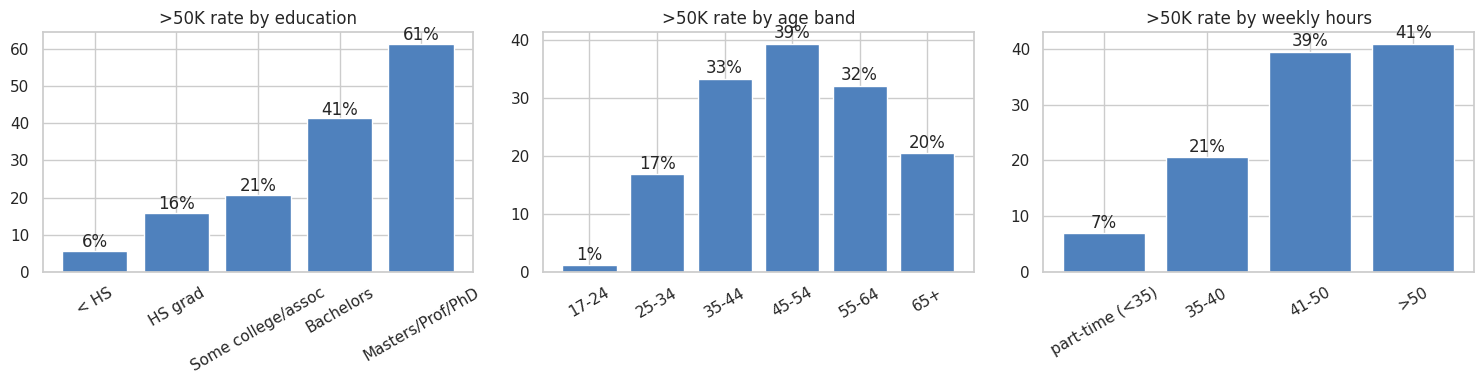

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c, tt in [(ax[0], "edu_group", ">50K rate by education"), (ax[1], "age_band", ">50K rate by age band"), (ax[2], "hours_band", ">50K rate by weekly hours")]:
    s = R[c].rate * 100; a.bar(s.index.astype(str), s.values, color="#4f81bd"); a.set_title(tt); a.tick_params(axis="x", rotation=30); [a.text(i, v + 1, f"{v:.0f}%", ha="center") for i, v in enumerate(s.values)]
save("01_rate_education_age_hours")

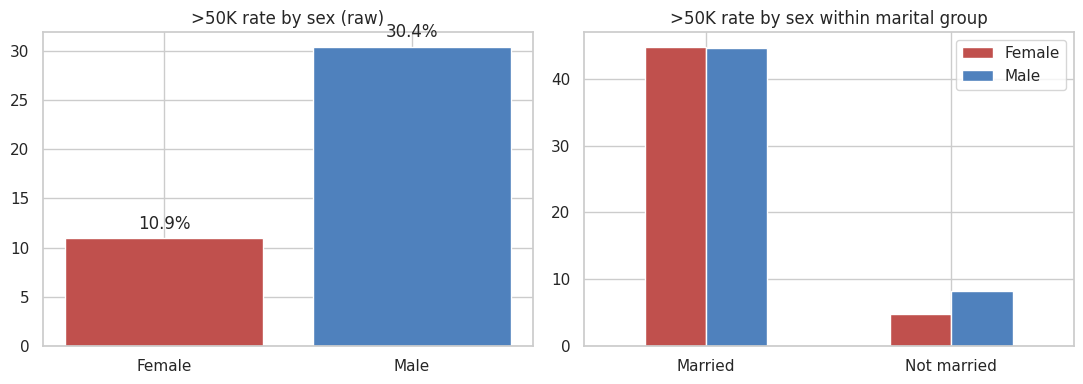

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4)); s = R["sex"].rate * 100; ax[0].bar(s.index, s.values, color=["#c0504d", "#4f81bd"]); ax[0].set_title(">50K rate by sex (raw)"); [ax[0].text(i, v + 1, f"{v:.1f}%", ha="center") for i, v in enumerate(s.values)]
mm = df.groupby(["married", "sex"]).y.mean().unstack() * 100; mm.plot.bar(ax=ax[1], color=["#c0504d", "#4f81bd"], rot=0); ax[1].set_title(">50K rate by sex within marital group"); ax[1].set_xlabel(""); ax[1].legend(title="")
M["rate_married_sex"] = mm.round(1).reset_index().to_dict("records"); save("02_sex_gap_marital")

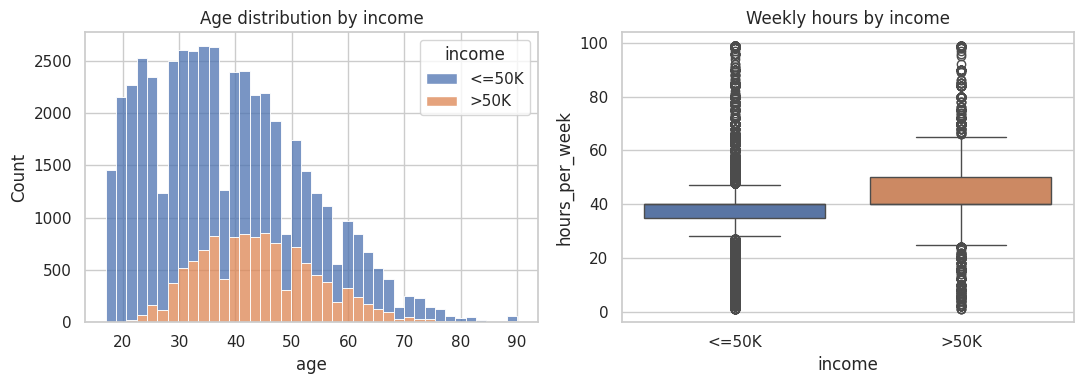

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4)); sns.histplot(data=df, x="age", hue="income", bins=40, multiple="stack", ax=ax[0]).set_title("Age distribution by income")
sns.boxplot(data=df, x="income", y="hours_per_week", hue="income", legend=False, ax=ax[1]).set_title("Weekly hours by income"); save("03_age_hours")

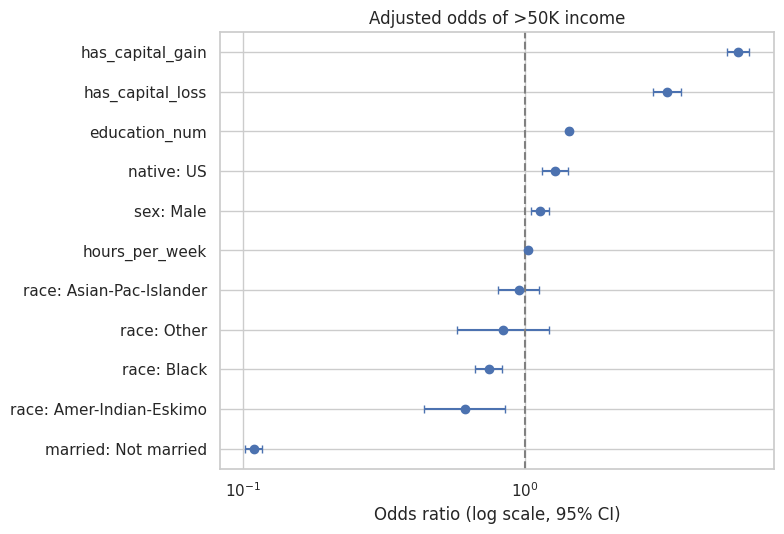

In [26]:
o = orx.drop(index=[i for i in orx.index if i in ("age", "I(age ** 2)")]).sort_values("OR"); plt.figure(figsize=(8, 5.5)); plt.errorbar(o.OR, range(len(o)), xerr=[o.OR - o.lo, o.hi - o.OR], fmt="o", capsize=3)
plt.axvline(1, c="gray", ls="--"); plt.xscale("log"); plt.yticks(range(len(o)), o.index); plt.xlabel("Odds ratio (log scale, 95% CI)"); plt.title("Adjusted odds of >50K income"); save("04_odds_ratios")

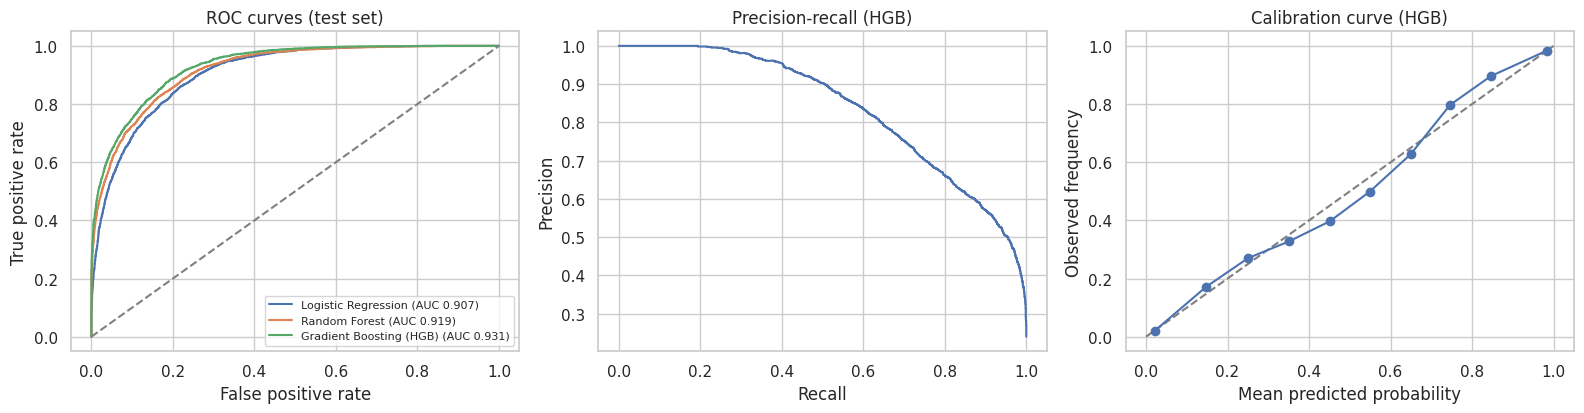

In [27]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for nme, m in fit.items():
    if "Baseline" in nme: continue
    fpr_, tpr_, _ = roc_curve(yte, m.predict_proba(Xte)[:, 1]); ax[0].plot(fpr_, tpr_, label=f"{nme} (AUC {roc_auc_score(yte, m.predict_proba(Xte)[:, 1]):.3f})")
ax[0].plot([0, 1], [0, 1], "--", c="gray"); ax[0].set(title="ROC curves (test set)", xlabel="False positive rate", ylabel="True positive rate"); ax[0].legend(fontsize=8)
pp, rr, _ = precision_recall_curve(yte, pr); ax[1].plot(rr, pp); ax[1].set(title="Precision-recall (HGB)", xlabel="Recall", ylabel="Precision")
ax[2].plot([0, 1], [0, 1], "--", c="gray"); ax[2].plot(ct_.mean_pred, ct_.actual, marker="o"); ax[2].set(title="Calibration curve (HGB)", xlabel="Mean predicted probability", ylabel="Observed frequency")
save("05_roc_pr_calibration")

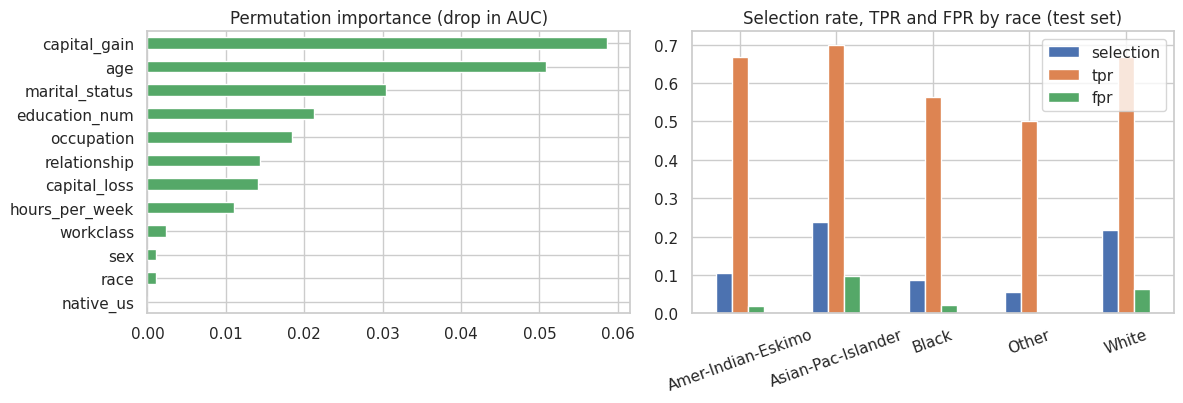

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2)); imp.sort_values().plot.barh(ax=ax[0], color="C2"); ax[0].set_title("Permutation importance (drop in AUC)")
a = fa_race.set_index("group")[["selection", "tpr", "fpr"]]; a.plot.bar(ax=ax[1], rot=20); ax[1].set_title("Selection rate, TPR and FPR by race (test set)"); ax[1].set_xlabel("")
save("06_importance_fairness")

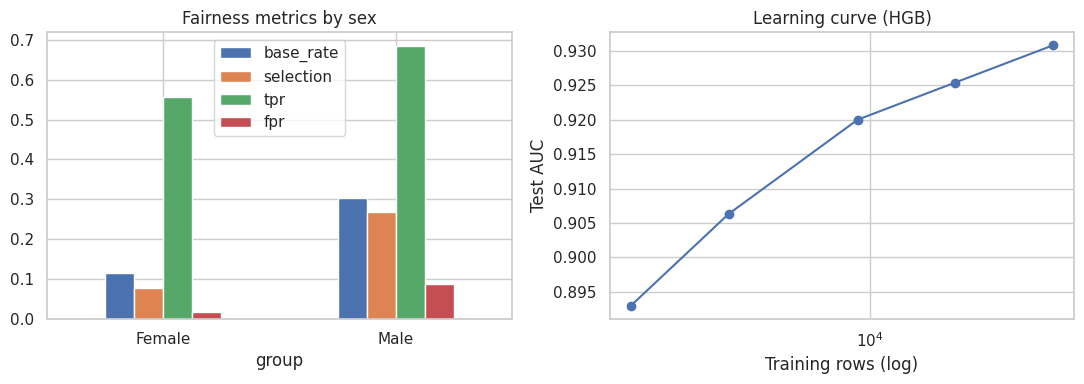

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4)); a = fa_sex.set_index("group")[["base_rate", "selection", "tpr", "fpr"]]; a.plot.bar(ax=ax[0], rot=0); ax[0].set_title("Fairness metrics by sex")
ax[1].plot(lc.train_rows, lc.test_auc, marker="o"); ax[1].set_xscale("log"); ax[1].set(title="Learning curve (HGB)", xlabel="Training rows (log)", ylabel="Test AUC"); save("07_sex_fairness_learning_curve")

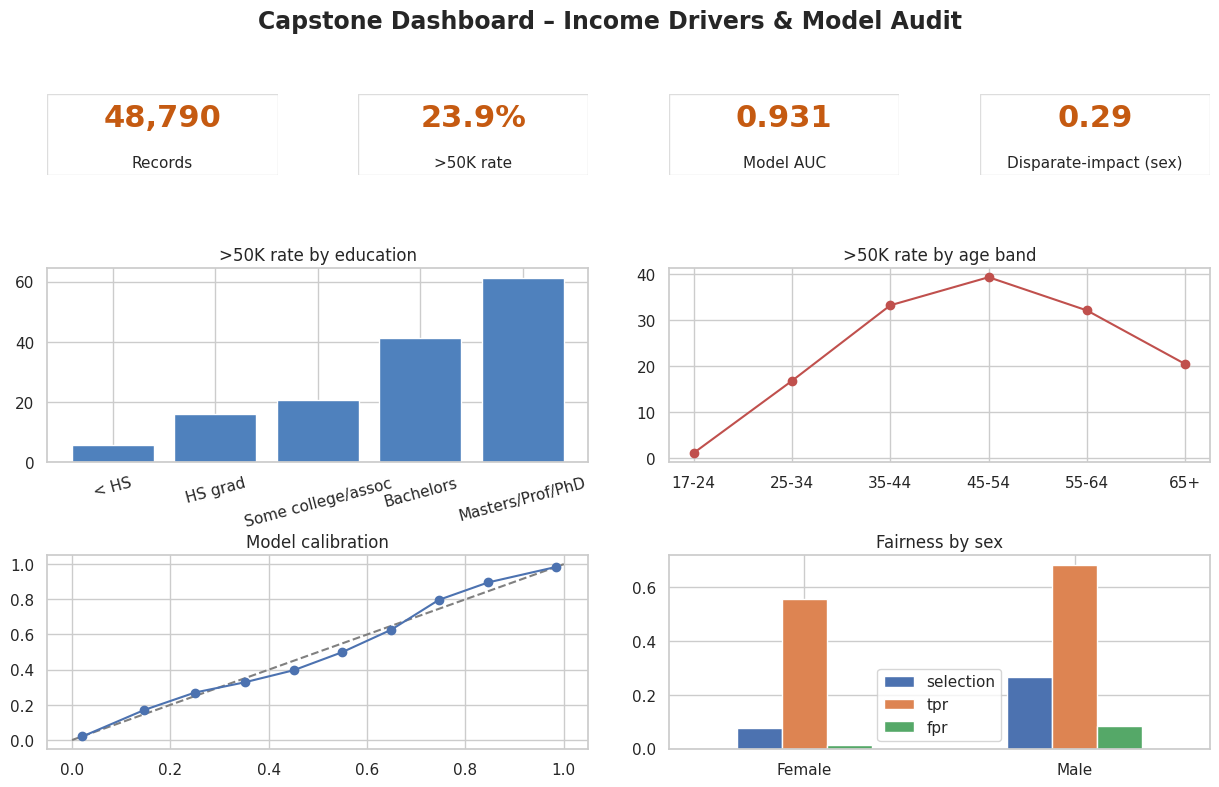

In [30]:
from matplotlib.gridspec import GridSpec
fig = plt.figure(figsize=(15, 8.5)); gs = GridSpec(3, 4, figure=fig, height_ratios=[0.5, 1.2, 1.2], hspace=0.6, wspace=0.35)
kp = [("Records", f"{n:,}"), (">50K rate", f"{df.y.mean():.1%}"), ("Model AUC", f"{M['auc']:.3f}"), ("Disparate-impact (sex)", f"{abl.iloc[0].di_ratio:.2f}")]
for i, (k, v) in enumerate(kp):
    a = fig.add_subplot(gs[0, i]); a.axis("off"); a.text(.5, .6, v, ha="center", fontsize=22, weight="bold", color="#c55a11"); a.text(.5, .1, k, ha="center", fontsize=11); a.add_patch(plt.Rectangle((0, 0), 1, 1, fill=False, ec="#ddd", transform=a.transAxes))
a = fig.add_subplot(gs[1, 0:2]); s = R["edu_group"].rate * 100; a.bar(s.index.astype(str), s.values, color="#4f81bd"); a.set_title(">50K rate by education"); a.tick_params(axis="x", rotation=15)
a = fig.add_subplot(gs[1, 2:4]); s = R["age_band"].rate * 100; a.plot(s.index.astype(str), s.values, marker="o", c="#c0504d"); a.set_title(">50K rate by age band")
a = fig.add_subplot(gs[2, 0:2]); a.plot([0, 1], [0, 1], "--", c="gray"); a.plot(ct_.mean_pred, ct_.actual, marker="o"); a.set_title("Model calibration")
a = fig.add_subplot(gs[2, 2:4]); fa_sex.set_index("group")[["selection", "tpr", "fpr"]].plot.bar(ax=a, rot=0); a.set_title("Fairness by sex"); a.set_xlabel("")
fig.suptitle("Capstone Dashboard – Income Drivers & Model Audit", fontsize=17, weight="bold", y=0.98); save("00_dashboard")

## 9. Insights, Possible Reasons and Limits of Interpretation
(The numeric statements are generated from the analysis above; the explanations are hypotheses.)

In [31]:
print(f"1. Education: >50K rate climbs from {R['edu_group'].rate.iloc[0]:.1%} (< HS) to {R['edu_group'].rate.iloc[-1]:.1%} (Masters/Prof/PhD).")
print(f"2. Age: rate peaks at {R['age_band'].rate.idxmax()} ({R['age_band'].rate.max():.1%}) and falls after 55 - wages rise with experience, then retirement/part-time work reduces income.")
print(f"3. Hours: {R['hours_band'].rate.iloc[0]:.1%} for part-time vs {R['hours_band'].rate.iloc[-1]:.1%} for >50 h/week.")
print(f"4. Marital status: married people earn >50K at {R['married'].loc['Married', 'rate']:.1%} vs {R['married'].loc['Not married', 'rate']:.1%} - partly a household-income/age effect.")
print(f"5. Sex: raw gap {M['sex_gap']:.1f} pp (OR {M['sex_or'][0]['OR']:.2f}) falls to OR {M['sex_or'][2]['OR']:.2f} after adjustment but does not vanish.")
print(f"6. Model: AUC {M['auc']:.3f} (95% CI {M['auc_lo']:.3f}-{M['auc_hi']:.3f}), accuracy {accuracy_score(yte, yh):.3f} vs baseline {M['base_acc']:.3f}; recall at 0.5 is only {recall_score(yte, yh):.1%}.")
print(f"7. Fairness: disparate-impact ratio by sex = {abl.iloc[0].di_ratio:.2f} (below the 0.80 rule of thumb); removing sex changes it only to {abl.iloc[1].di_ratio:.2f}.")

1. Education: >50K rate climbs from 5.7% (< HS) to 61.4% (Masters/Prof/PhD).
2. Age: rate peaks at 45-54 (39.4%) and falls after 55 - wages rise with experience, then retirement/part-time work reduces income.
3. Hours: 6.9% for part-time vs 40.9% for >50 h/week.
4. Marital status: married people earn >50K at 44.6% vs 6.4% - partly a household-income/age effect.
5. Sex: raw gap 19.5 pp (OR 3.56) falls to OR 1.18 after adjustment but does not vanish.
6. Model: AUC 0.931 (95% CI 0.925-0.935), accuracy 0.875 vs baseline 0.761; recall at 0.5 is only 66.5%.
7. Fairness: disparate-impact ratio by sex = 0.29 (below the 0.80 rule of thumb); removing sex changes it only to 0.30.


## 10. Limitations and Potential Biases
**Data and sampling**
- **Age of data:** 1994 census extract – wages, education returns, gender roles and the $50K threshold (a fixed nominal value) are very different today.
- **Label bias:** income is dichotomised at $50K; people just above and below are treated as different, and the label hides most variation. Top-coded values (capital gain 99,999; age 90) are placeholders, not real measurements.
- **Sampling weights:** the census weight (`fnlwgt`) was *not* applied, so results describe the sample, not the US population.
- **Missing not at random:** people with missing occupation/workclass have a much lower >50K rate (section 2.2); they were kept as "Unknown" instead of deleted, but missingness may mask other differences.
- **Small groups:** some race groups are small (e.g. American-Indian-Eskimo, Other), so group metrics have wide confidence intervals (section 7).

**Analysis and inference**
- **Observational data:** all relationships are associations; confounding (marital status, age) is visible in section 4.6, and unmeasured variables (experience, industry, region, career breaks) remain.
- **Multiple testing and large n:** with 48,000 rows nearly every test is significant; Holm correction and effect sizes were used to avoid over-reading p-values.
- **Marital status coding:** in this dataset it partly reflects household structure, so it cannot be interpreted as an individual effect.

**Model**
- **Class imbalance:** only about one quarter of people are >50K; at the default 0.5 threshold one third (33.5%) of true high earners are missed, and the threshold must be chosen deliberately (5.1).
- **Calibration and shift:** the model is well calibrated overall (Brier 0.087, ECE 0.014) but slightly over-confident in the 0.4–0.6 range and under-confident at 0.7–0.9 (6.1). The age-shift test showed only modest degradation (6.3), but temporal shift cannot be tested and is likely much larger.
- **Proxy discrimination:** deleting sex/race does not remove their influence (7.1).
- **Fairness definitions conflict:** it is mathematically impossible to equalise selection rates, error rates and calibration at once when group base rates differ.
- **Intended use:** suitable for exploring patterns and prioritising outreach, *not* for decisions about credit, employment or benefits for individuals.

## 11. Recommendations
1. **Use the findings to design programmes, not to score individuals:** education access, part-time-to-full-time pathways and mid-career support are the levers with the clearest association with higher income.
2. **If the model is used for outreach, set the threshold deliberately** (best F1 threshold in 5.1), publish group-level metrics, and review them every cycle.
3. **Do not rely on removing sensitive columns.** Add fairness constraints or post-processing, and test the result with the audit in section 7.
4. **Refresh the data.** Re-run the whole pipeline on current survey data (with sampling weights) before any real deployment.
5. **Future scope:** apply survey weights, add causal methods (matching, difference-in-differences where panel data exist), try monotonic-constrained boosting for interpretability, and evaluate group-specific calibration.

In [32]:
json.dump(M, open("data/metrics.json", "w"), indent=1, default=float); print("metrics.json saved:", len(M), "entries")

metrics.json saved: 87 entries
